In [1]:

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

import ground_truth, ica_methods, gd_methods, scoring


In [2]:
# no noise or corruption for the moment. 
m, k, d, n = 30, 15, 25, 20000
p_noise, p_corrupt = 0, 0 
seed = 0
V_star, U_star, X, A = ground_truth.generate_ground_truth(d, k, m, n, p_noise, p_corrupt, seed)

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print(dev)
X_t = torch.tensor(X, dtype=torch.float64, device=dev)
A_t = torch.tensor(A, dtype=torch.float64, device=dev)


S_oracle = V_star @ X > 0

cpu


In [3]:
# checking validity of the linear algebra method under oracle sparsity

U_ho, V_ho, misc_o = ica_methods.ica_exact_recovery_pipeline(A, X, k, ell=1000, tau=None, random_state=0, method='svd', S_override=S_oracle)
_, _, U_or, V_or, _ = scoring.align_and_score(U_ho, V_ho, U_star, V_star)
print(f"U recovery error: {U_or}")
print(f"V recovery error: {V_or}")

U recovery error: 1.0003345657628897e-12
V recovery error: 1.0000958345928085e-12


In [4]:
# end to end implementation of algorithm 4
# best tau seems to be ~0.085 with 100000 samples, but 0.212 for 20000
U_h4, V_h4, misc_h4 = ica_methods.ica_exact_recovery_pipeline(A, X, k, ell=500, tau=None, random_state=0, method='svd')
_, _, U_h4r, V_h4r, h4_perm = scoring.align_and_score(U_h4, V_h4, U_star, V_star)
S_recovered = misc_h4["S"]
sparsity_info = ica_methods.sparsity_diagnosis(S_recovered, S_oracle, h4_perm)

subspace = scoring.subspace_metric(U_h4, V_h4, U_star, V_star)
V_init_alignment, U_init_alignment = subspace["V_max"], subspace["U_max"]
print(f"V and U initialisation max subspace angles: {V_init_alignment}, {U_init_alignment}")

print(f"U recovery error: {U_h4r}")
print(f"V recovery error: {V_h4r}")
print(f"Intermediate sparsity error rate: {sparsity_info['err_rate']}, false negative rate: {sparsity_info['fn_rate']}")


V and U initialisation max subspace angles: 0.030924969013407914, 0.012785571801647102
U recovery error: 0.008165156870575058
V recovery error: 0.014450091247095348
Intermediate sparsity error rate: 0.07053333333333334, false negative rate: 0.07013333333333334


In [5]:
# investigation of ICA inherent error vs thresholding bottleneck
# run with oracle TU*

from scipy.optimize import linear_sum_assignment

ell, tau = 500, 0.0001
T, TU_hat, F_hat = ica_methods.sketch_and_run_ICA(A, k, random_state=0)
TA_bar = T @ A[:, :ell]

F_bar_oracle = np.linalg.solve(T @ U_star, TA_bar)
S_oracle_mix = F_bar_oracle > tau
S_true = np.maximum(V_star @ X[:, :ell], 0) > 0
print("support err with true TU*:", (S_oracle_mix != S_true).mean())
print("oracle row stds:", F_bar_oracle.std(axis=1)[:3], "  expect ~0.5838")

for t in [0.0001, 0.01, 0.02, 0.05, 0.1, 0.15, 0.212]:
    S_or  = F_bar_oracle > t
    S_ica = F_hat[:, :ell] > t
    e_or  = (S_or  != S_true).mean()
    # ICA rows are permuted — need the Hungarian match here
    C = np.array([[(S_ica[i] != S_true[j]).mean() for j in range(k)] for i in range(k)])
    r, c = linear_sum_assignment(C)
    e_ica = C[r, c].mean()
    print(f"tau={t:<7} oracle={e_or:.4f}  ica={e_ica:.4f}  gap={e_ica-e_or:.4f}")

support err with true TU*: 0.0
oracle row stds: [0.59620213 0.64049984 0.57765479]   expect ~0.5838
tau=0.0001  oracle=0.0000  ica=0.2573  gap=0.2573
tau=0.01    oracle=0.0039  ica=0.2176  gap=0.2137
tau=0.02    oracle=0.0084  ica=0.1811  gap=0.1727
tau=0.05    oracle=0.0204  ica=0.0909  gap=0.0705
tau=0.1     oracle=0.0425  ica=0.0516  gap=0.0091
tau=0.15    oracle=0.0621  ica=0.0633  gap=0.0012
tau=0.212   oracle=0.0871  ica=0.0873  gap=0.0003


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import linear_sum_assignment

taus = np.linspace(0.005, 0.3, 40)

# sigma_hat and predicted tau*

F = F_hat[:, :ell]
sig = np.sqrt(np.mean(F[F < 0]**2))

# match ICA rows to truth once (permutation doesn't depend on tau)
C = np.array([[np.mean((F[i] > 0.1) != S_true[j]) for j in range(k)] for i in range(k)])
r, c = linear_sum_assignment(C)
F_m = np.empty_like(F); F_m[c] = F[r]

e_or, e_ica, eps_V = [], [], []
for t in taus:
    e_or.append(np.mean((F_bar_oracle > t) != S_true))
    e_ica.append(np.mean((F_m > t) != S_true))
    U_h, V_h, _ = ica_methods.ica_exact_recovery_pipeline(A, X, k, ell=ell, tau=t, random_state=0, method='svd')
    eps_V.append(scoring.align_and_score(U_h, V_h, U_star, V_star)[3])

fn_pred = norm.cdf(taus) - 0.5
fp_pred = 0.5 * (1 - norm.cdf(taus / sig))


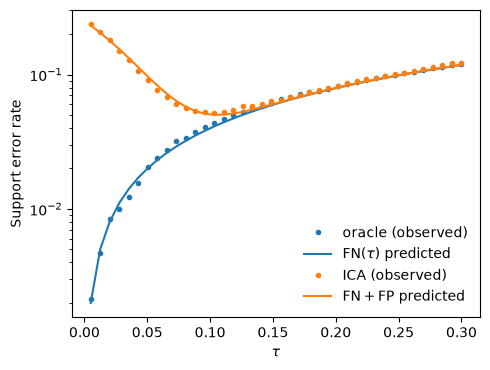

sigma_hat=0.0493  tau*=0.171


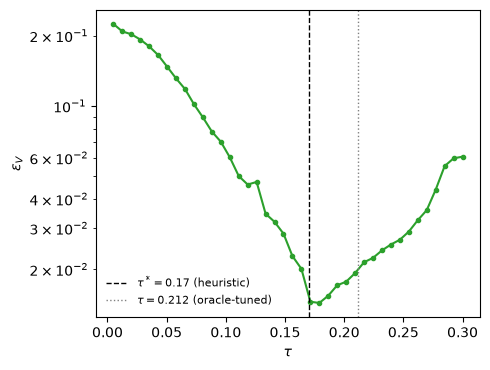

In [7]:
# left: support error
fig, a1 = plt.subplots(figsize=(5, 3.8))
a1.plot(taus, e_or, "o", ms=3, color="C0", label="oracle (observed)")
a1.plot(taus, fn_pred, "-", color="C0", label=r"$\mathrm{FN}(\tau)$ predicted")
a1.plot(taus, e_ica, "o", ms=3, color="C1", label="ICA (observed)")
a1.plot(taus, fn_pred + fp_pred, "-", color="C1", label=r"$\mathrm{FN}+\mathrm{FP}$ predicted")
a1.set_xlabel(r"$\tau$"); a1.set_ylabel("Support error rate"); a1.set_yscale("log")
a1.legend(frameon=False, fontsize=10)
fig.tight_layout()

plt.show()




tau_star = sig * norm.ppf(1 - 2 / (k * ell))

print(f"sigma_hat={sig:.4f}  tau*={tau_star:.3f}")


# right: recovery error
fig, a2 = plt.subplots(figsize=(5, 3.8))
a2.plot(taus, eps_V, "o-", ms=3, color="C2")
a2.axvline(tau_star, ls="--", color="k", lw=1, label=rf"$\tau^*={tau_star:.2f}$ (heuristic)")
a2.axvline(0.212, ls=":", color="grey", lw=1, label=r"$\tau=0.212$ (oracle-tuned)")
a2.set_xlabel(r"$\tau$"); a2.set_ylabel(r"$\varepsilon_V$"); a2.set_yscale("log")
a2.legend(frameon=False, fontsize=8)
fig.tight_layout()

plt.show()

In [8]:
# asymmetric cost of support errors

import numpy as np

F_true = np.maximum(V_star @ X[:, :ell], 0)
S_true = F_true > 0
rng = np.random.default_rng(0)
counts = [0, 5, 10, 20, 40, 80]

for kind in ("fn", "fp"):
    errs = []
    for nf in counts:
        S = S_true.copy()
        for j in range(k):
            if kind == "fn":
                # smallest true positives, matches what a threshold actually cuts
                pos = np.flatnonzero(S_true[j])
                pick = pos[np.argsort(F_true[j, pos])[:nf]]
                S[j, pick] = False
            else:
                zer = np.flatnonzero(~S_true[j])
                pick = rng.choice(zer, size=nf, replace=False)
                S[j, pick] = True
        _, V, _ = ica_methods.ica_exact_recovery_pipeline(
            A, X, k, ell=ell, random_state=0, S_override=S)
        _, _, _, eV, _ = scoring.align_and_score(U_star, V, U_star, V_star)
        errs.append(eV)
    print(kind, np.round(errs, 6))
    

fn [0.       0.000649 0.001554 0.004064 0.016037 0.144875]
fp [0.       0.049137 0.058922 0.082844 0.120627 0.143504]


U recovery error: 1.090942723847902e-12
V recovery error: 1.1021556873823371e-12
best iterate: 5673


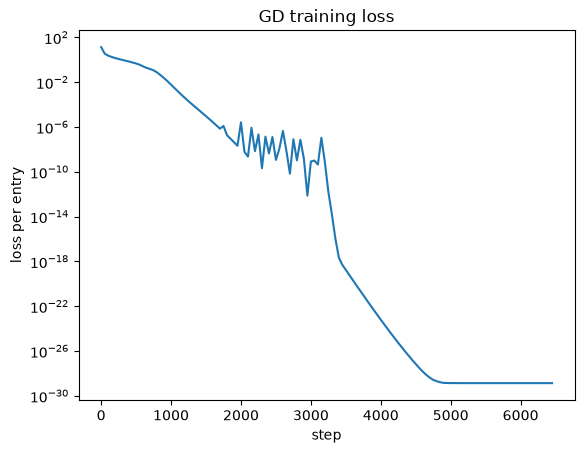

In [9]:
# gradient descent baseline - uses Adam optimiser
# default params
# Thesis shows 8000 steps, but we illustrate the difference acheived when keeping the same  number of steps
# consequence of cosine annealing
U_hgd, V_hgd, loss_randgd, best_step = gd_methods.train_gd(X_t, A_t, k, cosine=True, n_steps=6500)

_, _, U_gdr, V_gdr, _ = scoring.align_and_score(U_hgd, V_hgd, U_star, V_star)
print(f"U recovery error: {U_gdr}")
print(f"V recovery error: {V_gdr}")
print(f"best iterate: {best_step}")

gd_methods.loss_graph(loss_randgd[0], loss_randgd[1])

V and U initialisation max subspace angles: 0.030924969013407914, 0.012785571801647102
U param recovery error: 9.94040861556852e-13
V param recovery error: 9.941523253279875e-13
Intermediate sparsity error rate: 0.07053333333333334, false negative rate: 0.07013333333333334


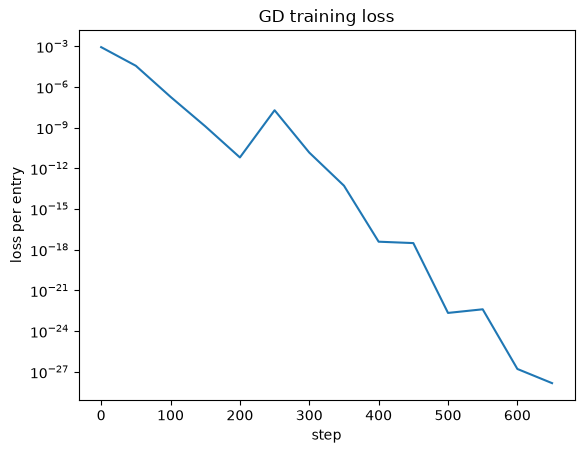

best iterate: 671


In [10]:
# ica initialisation - achieved exact recovery with gd and converged quicker but the raw ICA gave weak estimates.
# converges at 652 steps with cosine annealing - even better than what was written in the thesis!
U_hicagd, V_hicagd, loss_ica, best_step, misc_ica_gd, U_init, V_init = ica_methods.ica_exact_gd(A, X, k, ell=500, tau=None, random_state=0, method='svd', cosine=True, lr=0.01, n_steps=700)
_, _, U_icagdr, V_icagdr, gd_perm = scoring.align_and_score(U_hicagd, V_hicagd, U_star, V_star)
S_rec_gd = misc_ica_gd["S"]
sparsity_info_icagd = ica_methods.sparsity_diagnosis(S_rec_gd, S_oracle, gd_perm)
subspace = scoring.subspace_metric(U_init, V_init, U_star, V_star)
V_init_alignment, U_init_alignment = subspace["V_max"], subspace["U_max"]
print(f"V and U initialisation max subspace angles: {V_init_alignment}, {U_init_alignment}")


print(f"U param recovery error: {U_icagdr}")
print(f"V param recovery error: {V_icagdr}")
print(f"Intermediate sparsity error rate: {sparsity_info_icagd['err_rate']}, false negative rate: {sparsity_info_icagd['fn_rate']}")
gd_methods.loss_graph(loss_ica[0], loss_ica[1])
print(f"best iterate: {best_step}")

V and U initialisation max subspace angles: 1.1880585912537633, 1.3897896467159105
U recovery error: 1.0398468593003164e-12
V recovery error: 1.041666812843238e-12
best iterate: 6075


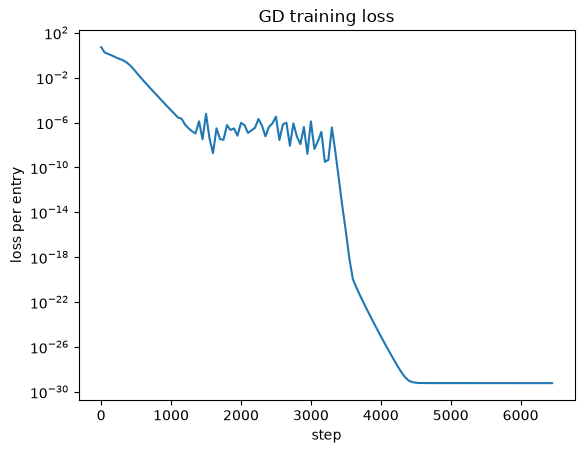

In [11]:
# now spectral initialisation GD - diagnose similarly with subspace angle!

U_spectral_init, V_spectral_init = ica_methods.spectral_initialisation(A, X, k)

spectral_subspace = scoring.subspace_metric(U_spectral_init, V_spectral_init, U_star, V_star)
V_spec_alignment, U_spec_alignment = spectral_subspace["V_max"], spectral_subspace["U_max"]
print(f"V and U initialisation max subspace angles: {V_spec_alignment}, {U_spec_alignment}")

U_hspectral, V_hspectral, loss_spectral, best_step = gd_methods.train_gd(X_t, A_t, k, n_steps=6500, lr=0.01, seed=None, unit_norm_V=True,
              log_every=50, U_init=U_spectral_init, V_init=V_spectral_init, cosine=True)

_, _, U_sr, V_sr, _ = scoring.align_and_score(U_hspectral, V_hspectral, U_star, V_star)
print(f"U recovery error: {U_sr}")
print(f"V recovery error: {V_sr}")
print(f"best iterate: {best_step}")


gd_methods.loss_graph(loss_spectral[0], loss_spectral[1])


In [12]:
# empirical verification of our closed form Hessian

import numpy as np, torch

# n = 200 to reduce computation

d, k, m, n = 25, 15, 30, 200

rng = np.random.default_rng(0)
_, _, X, A = ground_truth.generate_ground_truth(d=d, k=k, m=m, n=n)

U = rng.standard_normal((m, k)); V = rng.standard_normal((k, d))

H_mine = gd_methods.compute_hessian(U, V, X, A)["H"]

p, q = m*k, k*d 
def f_flat(z):
    Uh = z[:p].reshape(k, m).T
    Vh = z[p:].reshape(d, k).T
    return torch.sum((torch.tensor(A) - Uh @ torch.relu(Vh @ torch.tensor(X)))**2)

vec = lambda P: P.reshape(-1, order='F')
z0 = torch.tensor(np.concatenate([vec(U), vec(V)]), requires_grad=True)
H_auto = torch.autograd.functional.hessian(f_flat, z0).numpy()

print(abs(H_mine - H_auto).max())




1.0913936421275139e-11


In [13]:
# testing S-ceiling lemma using low dimensions

d, k, m, n = 6, 4, 8, 2000
p_noise, p_corrupt = 0, 0 

V_star, U_star, X, A = ground_truth.generate_ground_truth(d, k, m, n, p_noise, p_corrupt, seed)

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print(dev)
X_t = torch.tensor(X, dtype=torch.float64, device=dev)
A_t = torch.tensor(A, dtype=torch.float64, device=dev)



def perturbation_sweep(U_star, V_star, X, A, rs=(0, .01, .03, .05, .1, .2, .3, .4), seeds=5):
    """Perturb the ground truth along `seeds` random directions at each scale r and
    return the certificate diagnostics averaged over directions. `cert_frac` is the
    fraction of directions certified; `lam_perp_H_min` is the worst direction."""
    k = U_star.shape[1]
    Xnorm = np.linalg.norm(X, 2)
    rows = []
    for r in rs:
        for s in range(seeds):
            rng = np.random.default_rng(100 + s)          # same direction s at every r
            U = U_star + rng.standard_normal(U_star.shape) * r / np.sqrt(k)
            V = V_star + rng.standard_normal(V_star.shape) * r / np.sqrt(k)
            hd = gd_methods.hessian_diagnostics(U, V, X, A, Xnorm)
            hd["r"] = r
            rows.append(hd)
    df = pd.DataFrame(rows)
    out = df.groupby("r").mean().rename(columns={"cert": "cert_frac"})
    out["lam_perp_H_min"] = df.groupby("r")["lam_perp_H"].min()   # worst direction
    return out

perturbation_sweep(U_star, V_star, X, A, rs=(0, .01, .03, .05, .1, .2, .3, .4), seeds=5)

cpu


,resid,lamGN,rhs,cert_frac,S_full,S_proj,S_bound,weyl,lam_perp_H,lam_min_H,lam_perp_H_min
r,,,,,,,,,,,
0.00,0.000000,374.397851,8.153306,1.0,0.000000,0.000000,0.000000,748.795701,748.795701,-3.292351e-12,748.795701
0.01,2.553324,374.149056,8.147888,1.0,103.063110,76.524088,234.496041,645.235002,746.939008,-1.750694e+01,736.690089
0.03,7.651494,373.909112,8.142663,0.6,307.455801,229.552217,702.709579,440.362422,738.790474,-5.849817e+01,707.062140
0.05,12.738147,372.106549,8.103408,0.0,510.494926,382.351427,1169.865342,233.718173,723.065403,-1.075456e+02,671.260915
0.10,25.381335,362.350394,7.890947,0.0,1002.719068,762.784995,2331.009636,-278.018280,650.994580,-2.658747e+02,528.192206
0.20,50.468464,329.159988,7.168156,0.0,1984.992784,1531.132824,4634.999534,-1326.672809,410.794455,-7.167484e+02,59.494285
0.30,75.542823,291.976801,6.358413,0.0,2982.403591,2347.169039,6937.816607,-2398.449990,70.760079,-1.350867e+03,-678.805878
0.40,100.762425,267.611549,5.827808,0.0,3953.647812,3203.871862,9253.972730,-3418.424715,-360.726461,-2.156203e+03,-1683.579760


In [14]:
# seeing if ICA init falls under S-ceiling lemma

U_hat, V_hat, _ = ica_methods.ica_exact_recovery_pipeline(A, X, k, ell=500, tau=0.19, random_state=0, method='svd', S_override=None)

LHS = np.linalg.norm(U_hat @ np.maximum(V_hat @ X, 0) - A) / np.sqrt(n)
LHS

hd = gd_methods.hessian_diagnostics(U_hat, V_hat, X, A)
print(hd["cert"], hd["resid"]/np.sqrt(n), hd["rhs"]/np.sqrt(n), hd["lam_perp_H"]/n)

True 0.06650034332018574 0.18476899303639627 0.3790596454777389


In [ ]:
from itertools import product
import exp_run


# The oracle-tuned 0.212 in the thesis minimised support error; recovery error is
# minimised at a smaller tau, where false positives first vanish (see thesis Fig. 2).
# tau=None uses the heuristic tau* = sigma_hat * Phi^{-1}(1 - 2/(k*ell)).
#The heuristic τ assumes the only noise is ICA estimation error. 
# Under additive noise it’s inflated. This results in failures for this cell 
# fix tau = 0.19 for contamination runs.
# Algo4+GD’s best_step of about 1,800–2,000 with n_steps=2000 means it’s running against the end of its schedule. 
# It’s not a fair “steps to converge” number to set against GD’s 8,000. Only compare final errors from this sweep, not step counts.




configs2 = [{"d": 25, "k": 15, "m": 30, "n": n,
             "p_noise": pn, "p_corrupt": pc, "seed": s}
            for n, pn, pc, s in product([20000], [0, 0.1], [0, 0.1], range(3))]

methods2 = {
    "GD Baseline":       lambda cfg, gt: exp_run.run_gd_baseline(cfg, gt, n_steps=8000),
    "ICA Algo4":    lambda cfg, gt: exp_run.run_ica_algo4(cfg, gt, ell=500, tau=None),
    "Algo4+GD": lambda cfg, gt: exp_run.run_ica_exact_gd(cfg, gt, ell=500, tau=None),
}

sweep_df = exp_run.run_all(configs2, methods2, out="sweep_noise_contam.csv")
sweep_df.groupby(["method", "n", "p_noise", "p_corrupt"])[["U_err", "V_err"]].agg(["mean", "std"])

U_err                       V_err  \
                                             mean           std          mean   
method      n     p_noise p_corrupt                                             
Algo4+GD    20000 0.0     0.0        9.942739e-13  6.979923e-16  9.943741e-13   
                          0.1                 NaN           NaN           NaN   
                  0.1     0.0        1.277111e-03  2.072165e-05  1.052791e-03   
                          0.1                 NaN           NaN           NaN   
GD Baseline 20000 0.0     0.0        1.011603e-12  7.440836e-14  1.043204e-12   
                          0.1        1.308827e-01  2.414258e-03  4.335629e-02   
                  0.1     0.0        1.277112e-03  2.072143e-05  1.052599e-03   
                          0.1        1.308792e-01  2.450355e-03  4.336437e-02   
ICA Algo4   20000 0.0     0.0        2.657834e-02  2.641991e-02  4.142135e-02   
                          0.1                 NaN           NaN           NaN   
                  0.1     0.0        4.711722e-01  4.149107e-01  6.605871e-01   
                          0.1                 NaN           NaN           NaN   

                                                   
                                              std  
method      n     p_noise p_corrupt                
Algo4+GD    20000 0.0     0.0        6.471763e-16  
                          0.1                 NaN  
                  0.1     0.0        1.861039e-05  
                          0.1                 NaN  
GD Baseline 20000 0.0     0.0        5.133565e-14  
                          0.1        6.942565e-03  
                  0.1     0.0        1.872443e-05  
                          0.1        6.941885e-03  
ICA Algo4   20000 0.0     0.0        3.771369e-02  
                          0.1                 NaN  
                  0.1     0.0        5.598937e-01  
                          0.1                 NaN